## Daniel Barella
## 9/13/25

# 📅 Day 10 – Full EDA Workflow (Titanic Mini-Project)
## ✅ Goals

- Practice loading, cleaning, exploring, and visualizing data in one coherent workflow

- Generate questions → analysis → insights

- Document findings clearly

## 🔧 Step-by-Step Instructions
### 1. Imports & Data Load

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv(url)

# Inspect
titanic.head()
titanic.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


### 📌2. Cleaning Step

Make dataset consistent before analysis.

In [5]:
# Drop rows missing key survival info
titanic = titanic.dropna(subset=["Survived"])

# Fill missing Age with median
titanic["Age"].fillna(titanic["Age"].median(), inplace=True)

# Fill Embarked with mode
titanic["Embarked"].fillna(titanic["Embarked"].mode()[0], inplace=True)

# Convert Sex column
titanic.rename(columns={"Sex": "Gender"}, inplace=True)


### 3. Descriptive Stats

In [6]:
print(titanic.info())
print(titanic.describe(include="all"))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Gender       891 non-null    object 
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     891 non-null    object 
 12  FamilySize   891 non-null    int64  
 13  IsChild      891 non-null    bool   
 14  HighFare     891 non-null    bool   
dtypes: bool(2), float64(2), int64(6), object(5)
memory usage: 92.4+ KB
None
        PassengerId    Survived      Pclass                     Name Gender  \
count    891.000000  891.

### 4. Key Questions & Visualizations

1 Who survived more: men or women?

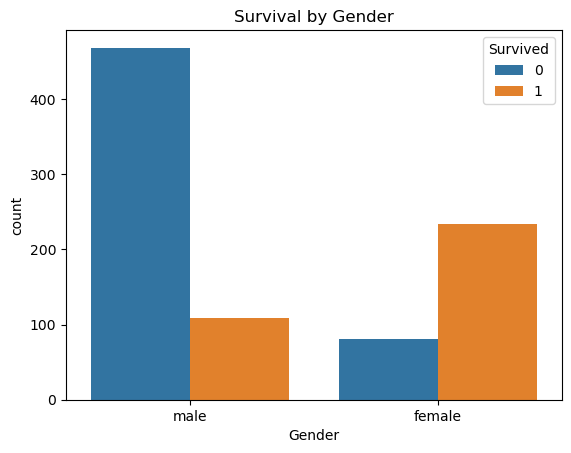

In [7]:
sns.countplot(x="Gender", hue="Survived", data=titanic)
plt.title("Survival by Gender")
plt.show()


2. Did class matter for survival?

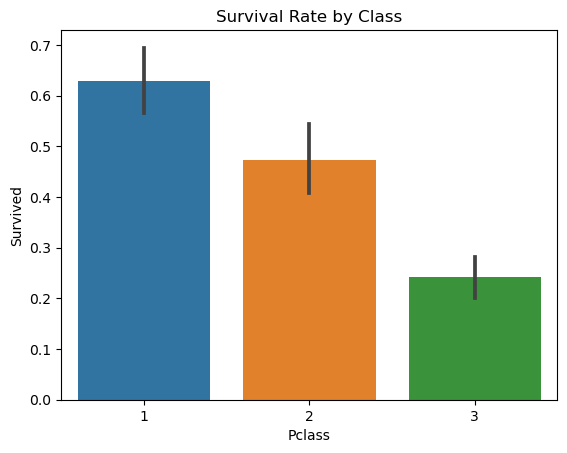

In [8]:
sns.barplot(x="Pclass", y="Survived", data=titanic)
plt.title("Survival Rate by Class")
plt.show()


3. How did age affect survival?


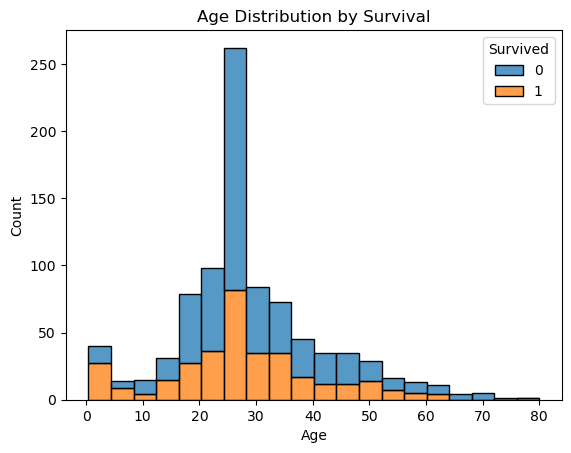

In [9]:
sns.histplot(data=titanic, x="Age", hue="Survived", multiple="stack", bins=20)
plt.title("Age Distribution by Survival")
plt.show()


4. Was fare linked to survival?

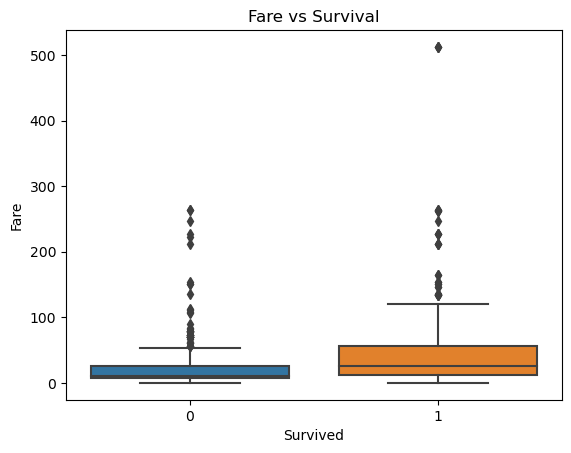

In [10]:
sns.boxplot(x="Survived", y="Fare", data=titanic)
plt.title("Fare vs Survival")
plt.show()


5. Correlation Check

### 🎯 Mini Project – Titanic EDA Report

Your task is to tell the survival story using your workflow:

- Cleaning → Exploration → Visualization → Interpretation

- At least 4 plots with explanations

- Write markdown cells summarizing insights like:

- “Women had a survival advantage compared to men.”

- “First class passengers survived more often than third class.”

## 🎯 Titanic EDA Report
### 🔹 Step 1: Cleaning

- Dropped/ignored columns with too many missing values (Cabin).

- Verified dataset size: 891 passengers, 15 columns.

- Created new features:

    - FamilySize = SibSp + Parch + 1

    - IsChild = Age < 12

    - HighFare = Fare > 50

### 🔹 Step 2: Exploration

- Overall survival rate: 38% survived.

- Gender distribution: 577 males, 314 females.

- Most passengers embarked from Southampton (S).

- Age range: 0.42 – 80 years, average ~29.

### 🔹 Step 3: Visualization & Findings
1️⃣ Survival by Passenger Class

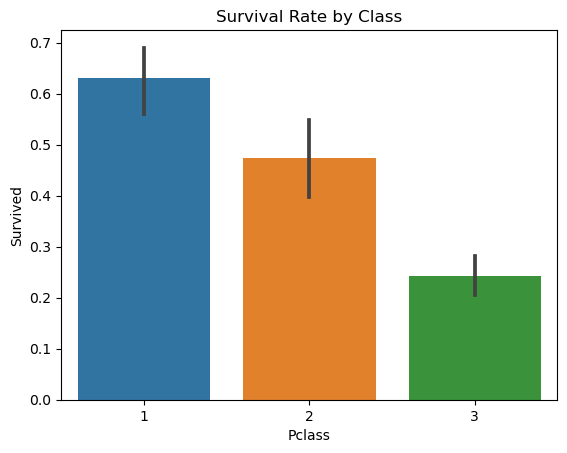

In [11]:
sns.barplot(x="Pclass", y="Survived", data=titanic)
plt.title("Survival Rate by Class")
plt.show()


Insight:

- 1st Class passengers had the highest survival rates.

- 3rd Class passengers had the lowest.

2️⃣ Survival by Gender

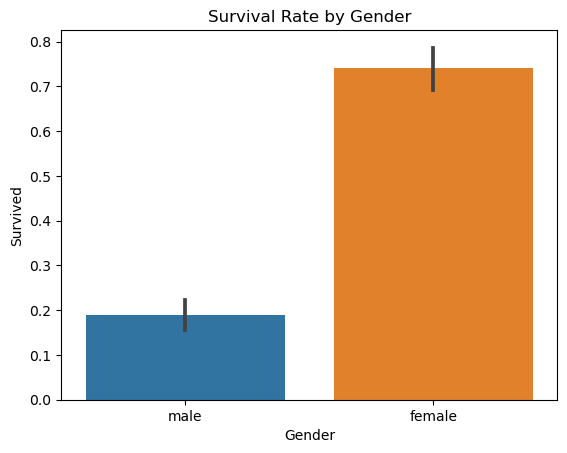

In [12]:
sns.barplot(x="Gender", y="Survived", data=titanic)
plt.title("Survival Rate by Gender")
plt.show()


Insight:

- Women had a strong survival advantage.

- Survival rate for women was much higher than for men.

3️⃣ Age Distribution of Survivors vs Non-Survivors

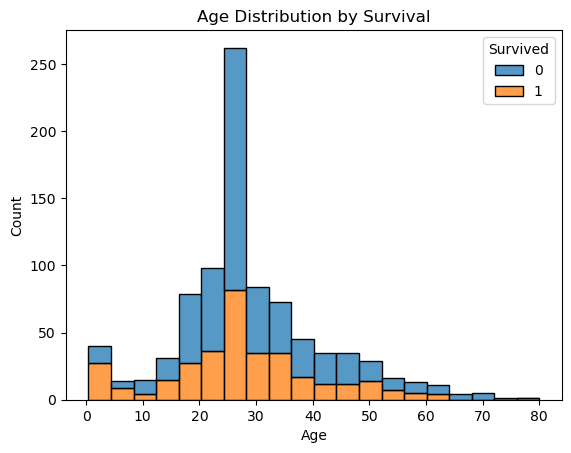

In [14]:
sns.histplot(titanic, x="Age", hue="Survived", multiple="stack", bins=20)
plt.title("Age Distribution by Survival")
plt.show()


Insight:

- Children had relatively better odds of survival.

- Survival among adults varied, but the elderly had lower chances.

4️⃣ Fare vs Age (Scatter Plot, colored by Survival)

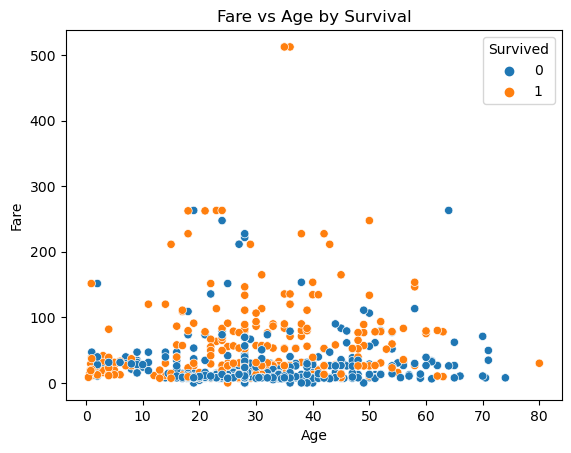

In [15]:
sns.scatterplot(x="Age", y="Fare", hue="Survived", data=titanic)
plt.title("Fare vs Age by Survival")
plt.show()


Insight:

- Higher fares (wealthier passengers) often linked to higher survival.

- Younger children also cluster in the survivor group.

5️⃣ Bonus: Correlation Heatmap

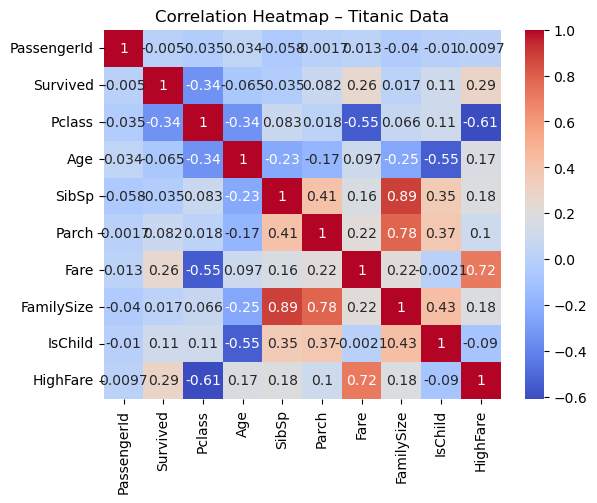

In [16]:
sns.heatmap(titanic.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap – Titanic Data")
plt.show()


Insight:

- Strongest correlation with survival: Gender, followed by Pclass and Fare.


### 🔹 Step 4: Interpretation

The survival story of the Titanic:

- Women and children had priority in rescue.

- Wealth (higher class, higher fares) improved chances of survival.

- Being in 3rd class and male reduced odds significantly.

- Age played a secondary role; young children had slightly better chances.